# Minimum Variance Analysis for selected intervals of Juno Magnetometer data.

In [1]:
import os
import re
import glob
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt

from matplotlib.ticker import AutoMinorLocator

from JunoPy.mag import MagData
from JunoPy.library import find_ticks_between

## 1. Specify epoch and identify the magnetometer file.

In [2]:
start = dt.datetime.strptime('2017-338T22:49:10', '%Y-%jT%H:%M:%S')
end   = dt.datetime.strptime('2017-338T22:50:10', '%Y-%jT%H:%M:%S')
magfile = glob.glob('data/mag/*{:s}ss*.hdf5'.format(start.strftime('%Y%j')))[0]
print('Magnetometer file to plot - {:s}'.format(magfile))

Magnetometer file to plot - data/mag/fgm_jno_l3_2017338ss_r1s_v01.hdf5


## 2. Read and crop the magnetometer file (+/- 10 minutes from epoch)

In [3]:
def read_and_crop(magfile, start, end):
    """Read and crop magnetometer data."""
    magdata = MagData(filename=magfile)
    start_cut = start - dt.timedelta(minutes=5)
    end_cut   = end   + dt.timedelta(minutes=5)
    magdata.df = magdata.df.loc[start_cut:end_cut]

    magdata_mva = MagData(filename=magfile)
    magdata_mva.df = magdata_mva.df.loc[start:end]
    magdata_mva.perform_mva()

    # print(magdata)
    return magdata, magdata_mva

magdata, magdata_mva = read_and_crop(magfile, start, end)

## 3. Create the MVA composite plot.

In [4]:
def plot_mva_composite(magdata, magdata_mva, start, end, savefile=False):

    fig = plt.figure(figsize=(11, 8.5), constrained_layout=False, dpi=300)

    gs1 = fig.add_gridspec(
        nrows=4, ncols=1, top=0.99, bottom=0.55, left=0.15, right=0.7, hspace=0)
    ax_magdata = list()
    for i in range(4):
        ax_magdata.append(fig.add_subplot(gs1[i, 0]))

    gs2 = fig.add_gridspec(
        nrows=3, ncols=1, top=0.45, bottom=0.1, left=0.15, right=0.66, hspace=0)
    ax_mvaB = list()
    for i in range(3):
        ax_mvaB.append(fig.add_subplot(gs2[i, 0]))

    gs3 = fig.add_gridspec(
        nrows=2, ncols=1, top=0.45, bottom=0.1, left=0.67, right=0.9, hspace=0)
    ax_hodo = list()
    for i in range(2):
        ax_hodo.append(fig.add_subplot(gs3[i, 0]))

    gs4 = fig.add_gridspec(
        nrows=1, ncols=1, top=0.9, bottom=0.55, left=0.71, right=0.9)
    ax_text = fig.add_subplot(gs4[0, 0])

    # 1. Plot the mag data +/- 10 min from epoch. ------------------------------------
    ax_magdata = magdata.plot(
        vars=['Br', 'Btheta', 'Bphi', 'Bmag'], axs=ax_magdata)
    timearray, tickstring = find_ticks_between(magdata.df.index[0], magdata.df.index[-1])
    ylabels = ['B$_r$', 'B$_\\theta$', 'B$_\phi$', '|B|']
    for i, a in enumerate(ax_magdata):
        a.set_xticks([], [])
        a.set_xticks(timearray)
        a.set_xticklabels(tickstring)
        a.set_ylabel(ylabels[i] + ' (nT)')
        a.set_xlim(magdata.df.index[0], magdata.df.index[-1])
        a.label_outer()
        if start and end:
            a.axvspan(start, end, alpha=0.2, color=[0.2, 0.2, 0.2])
    a.tick_params(axis='x', width=2, rotation=0)
    a.xaxis.label.set_visible(False)


    # 2. Plot the MVA B vectors. -------------------------------------------------------
    ax_mvaB = magdata_mva.plot(vars=['B1', 'B2', 'B3'], axs=ax_mvaB)
    timearray2, tickstring2 = find_ticks_between(magdata_mva.df.index[0], magdata_mva.df.index[-1])
    ylabels = ['B$_1$', 'B$_2$', 'B$_3$']
    for i, a in enumerate(ax_mvaB):
        a.set_xticks([], [])
        a.set_xticks(timearray2)
        a.set_xticklabels(tickstring2, fontdict={'horizontalalignment':'right'})
        a.set_xlim(magdata_mva.df.index[0], magdata_mva.df.index[-1])
        a.set_ylabel(ylabels[i] + ' (nT)')
        a.label_outer()

    a.tick_params(axis='x', width=2, rotation=0)
    a.xaxis.label.set_visible(False)

    dy = (ax_mvaB[-1].get_ylim()[1] - ax_mvaB[-1].get_ylim()[0]) / 2
    
    ax_mvaB[0].set_ylim([magdata_mva.df['B1'].mean() - dy,
                         magdata_mva.df['B1'].mean() + dy])
    ax_mvaB[1].set_ylim([magdata_mva.df['B2'].mean() - dy,
                         magdata_mva.df['B2'].mean() + dy])
    
    # 3. Plot the hodograms. -----------------------------------------------------------
    combo = [['B3', 'B1'],
             ['B3', 'B2']]
    Bmax = np.max(np.array(
            [magdata_mva.df['B1'].abs().max(), 
             magdata_mva.df['B2'].abs().max(), 
             magdata_mva.df['B3'].abs().max()]))  * 1.01
    
    
    for i, a in enumerate(ax_hodo):
        
        a.scatter(magdata_mva.df[combo[i][0]][0], magdata_mva.df[combo[i][1]][0], marker='o', color='b', s=50, label='Start')
        a.scatter(magdata_mva.df[combo[i][0]][-1], magdata_mva.df[combo[i][1]][-1], marker='x', color='r', s=50, label='End')
        a.plot(magdata_mva.df[combo[i][0]], magdata_mva.df[combo[i][1]],
               color='k',lw=0.4)
        
        a.set_xlabel(combo[i][0] + ' (nT)')
        a.set_ylabel(combo[i][1] + ' (nT)')
        a.set_aspect('equal', adjustable='datalim')
        a.xaxis.set_minor_locator(AutoMinorLocator())
        a.yaxis.set_minor_locator(AutoMinorLocator())
        a.grid('on', which='minor', lw=0.5, ls='dotted')
        a.grid(color='k', ls='dashed', lw=0.25)
        a.yaxis.tick_right()
        a.yaxis.set_label_position("right")
        a.label_outer()
    
    ax_hodo[0].legend(loc='upper right')
    ax_hodo[0].set_xlabel('B$_3$ (nT)')
    ax_hodo[0].set_ylabel('B$_1$ (nT)')
    ax_hodo[1].set_xlabel('B$_3$ (nT)')
    ax_hodo[1].set_ylabel('B$_2$ (nT)')
        
    # 4. Add Text ----------------------------------------------------------------------
    ax_text.axis('off')

    date = dt.datetime.strptime(start.strftime('%Y-%j'), '%Y-%j')

    text = []
    text.append(dt.datetime.strftime(date, '%Y-%m-%d') + ', DOY={:s}'.format(dt.datetime.strftime(date, '%j')))
    text.append('\n\n')
    text.append('MVA Output:\n--------\n\nCartesian Eigenvectors:\n')
    text.append('x$_1$ = ({:.2f}, {:.2f}, {:.2f})\n'.format(magdata_mva.x1[0], magdata_mva.x1[1], magdata_mva.x1[2]))
    text.append('x$_2$ = ({:.2f}, {:.2f}, {:.2f})\n'.format(magdata_mva.x2[0], magdata_mva.x2[1], magdata_mva.x2[2]))
    text.append('x$_3$ = ({:.2f}, {:.2f}, {:.2f})\n\n'.format(magdata_mva.x3[0], magdata_mva.x3[1], magdata_mva.x3[2]))
    text.append('--------\nRatio of eigenvalues:\n')
    text.append('$\lambda_3$ / $\lambda_2$ = {:.2f}\n'.format(magdata_mva.eigval[2] / magdata_mva.eigval[1]))
    text.append('$\lambda_2$ / $\lambda_1$ = {:.2f}\n'.format(magdata_mva.eigval[1] / magdata_mva.eigval[0]))
    text.append('$P = {:.2f}$\n'.format(magdata_mva.P))
    text = ''.join(text)
    ax_text.text(0.5, 0.5, text, horizontalalignment='center', verticalalignment='center',
                 bbox=dict(boxstyle="round",
                   ec=(0.9, 0.9, 0.9),
                   fc=(0.9, 0.9, 0.9),
                   ))
    
    if savefile:
        plotfile = 'out_mva/' + dt.datetime.strftime(start, '%Y-%jT%H:%M:%S')
        fig.savefig(plotfile)
        plt.close(fig)

In [5]:
def plot_mva_composite_xyz(magdata, magdata_mva, start, end, savefile=False):

    fig = plt.figure(figsize=(11, 8.5), constrained_layout=False, dpi=300)

    gs1 = fig.add_gridspec(
        nrows=4, ncols=1, top=0.99, bottom=0.55, left=0.15, right=0.7, hspace=0)
    ax_magdata = list()
    for i in range(4):
        ax_magdata.append(fig.add_subplot(gs1[i, 0]))

    gs2 = fig.add_gridspec(
        nrows=3, ncols=1, top=0.45, bottom=0.1, left=0.15, right=0.66, hspace=0)
    ax_mvaB = list()
    for i in range(3):
        ax_mvaB.append(fig.add_subplot(gs2[i, 0]))

    gs3 = fig.add_gridspec(
        nrows=2, ncols=1, top=0.45, bottom=0.1, left=0.67, right=0.9, hspace=0)
    ax_hodo = list()
    for i in range(2):
        ax_hodo.append(fig.add_subplot(gs3[i, 0]))

    gs4 = fig.add_gridspec(
        nrows=1, ncols=1, top=0.9, bottom=0.55, left=0.71, right=0.9)
    ax_text = fig.add_subplot(gs4[0, 0])

    # 1. Plot the mag data +/- 10 min from epoch. ------------------------------------
    ax_magdata = magdata.plot(
        vars=['Bx', 'By', 'Bz', 'Bmag'], axs=ax_magdata)
    timearray, tickstring = find_ticks_between(magdata.df.index[0], magdata.df.index[-1])
    ylabels = ['Bx', 'By', 'Bz', '|B|']
    for i, a in enumerate(ax_magdata):
        a.set_xticks(timearray)
        a.set_xticklabels(tickstring)
        a.set_ylabel(ylabels[i] + ' (nT)')
        a.set_xlim(magdata.df.index[0], magdata.df.index[-1])
        a.label_outer()
        if start and end:
            a.axvspan(start, end, alpha=0.2, color=[0.2, 0.2, 0.2])
    a.tick_params(axis='x', width=2, rotation=0)
    a.xaxis.label.set_visible(False)


    # 2. Plot the MVA B vectors. -------------------------------------------------------
    ax_mvaB = magdata_mva.plot(vars=['B1', 'B2', 'B3'], axs=ax_mvaB)
    timearray, tickstring = find_ticks_between(magdata_mva.df.index[0], magdata_mva.df.index[-1])
    ylabels = ['B$_1$', 'B$_2$', 'B$_3$']
    for i, a in enumerate(ax_mvaB):
        a.set_xticks(timearray)
        a.set_xticklabels(tickstring, fontdict={'horizontalalignment':'right'})
        a.set_xlim(magdata_mva.df.index[0], magdata_mva.df.index[-1])
        a.set_ylabel(ylabels[i] + ' (nT)')
        a.label_outer()

    a.tick_params(axis='x', width=2, rotation=0)
    a.xaxis.label.set_visible(False)
    dy = (ax_mvaB[-1].get_ylim()[1] - ax_mvaB[-1].get_ylim()[0]) / 2
    
    ax_mvaB[0].set_ylim([magdata_mva.df['B1'].mean() - dy,
                         magdata_mva.df['B1'].mean() + dy])
    ax_mvaB[1].set_ylim([magdata_mva.df['B2'].mean() - dy,
                         magdata_mva.df['B2'].mean() + dy])
    
    # 3. Plot the hodograms. -----------------------------------------------------------
    combo = [['B3', 'B1'],
             ['B3', 'B2']]
    Bmax = np.max(np.array(
            [magdata_mva.df['B1'].abs().max(), 
             magdata_mva.df['B2'].abs().max(), 
             magdata_mva.df['B3'].abs().max()]))  * 1.01
    
    
    for i, a in enumerate(ax_hodo):
    
        a.plot(magdata_mva.df[combo[i][0]], magdata_mva.df[combo[i][1]],
               color='k',lw=0.4)
        a.plot(magdata_mva.df[combo[i][0]][0], magdata_mva.df[combo[i][1]][0], '*')
        
        a.set_xlabel(combo[i][0] + ' (nT)')
        a.set_ylabel(combo[i][1] + ' (nT)')
        a.set_aspect('equal', adjustable='datalim')
        a.xaxis.set_minor_locator(AutoMinorLocator())
        a.yaxis.set_minor_locator(AutoMinorLocator())
        a.grid('on', which='minor', lw=0.5, ls='dotted')
        a.grid(color='k', ls='dashed', lw=0.25)
        a.yaxis.tick_right()
        a.yaxis.set_label_position("right")
        a.label_outer()
        
    ax_hodo[0].set_xlabel('B$_3$ (nT)')
    ax_hodo[0].set_ylabel('B$_1$ (nT)')
    ax_hodo[1].set_xlabel('B$_3$ (nT)')
    ax_hodo[1].set_ylabel('B$_2$ (nT)')
        
    # 4. Add Text ----------------------------------------------------------------------
    ax_text.axis('off')

    date = dt.datetime.strptime(start.strftime('%Y-%j'), '%Y-%j')

    text = []
    text.append(dt.datetime.strftime(date, '%Y-%m-%d') + ', DOY={:s}'.format(dt.datetime.strftime(date, '%j')))
    text.append('\n\n')
    text.append('MVA Output:\n--------\n\nCartesian Eigenvectors:\n')
    text.append('x$_1$ = ({:.2f}, {:.2f}, {:.2f})\n'.format(magdata_mva.x1[0], magdata_mva.x1[1], magdata_mva.x1[2]))
    text.append('x$_2$ = ({:.2f}, {:.2f}, {:.2f})\n'.format(magdata_mva.x2[0], magdata_mva.x2[1], magdata_mva.x2[2]))
    text.append('x$_3$ = ({:.2f}, {:.2f}, {:.2f})\n\n'.format(magdata_mva.x3[0], magdata_mva.x3[1], magdata_mva.x3[2]))
    text.append('--------\nRatio of eigenvalues:\n')
    text.append('$\lambda_3$ / $\lambda_2$ = {:.2f}\n'.format(magdata_mva.eigval[2] / magdata_mva.eigval[1]))
    text.append('$\lambda_2$ / $\lambda_1$ = {:.2f}\n'.format(magdata_mva.eigval[1] / magdata_mva.eigval[0]))
    text = ''.join(text)
    ax_text.text(0.5, 0.5, text, horizontalalignment='center', verticalalignment='center',
                 bbox=dict(boxstyle="round",
                   ec=(0.9, 0.9, 0.9),
                   fc=(0.9, 0.9, 0.9),
                   ))
    
    if savefile:
        plotfile = 'out_mva/' + dt.datetime.strftime(start, '%Y-%jT%H:%M:%S')
        fig.savefig(plotfile)
        plt.close(fig)

/home/ysar/anaconda3/envs/JunoPy-das/lib/python3.7/site-packages/ipykernel_launcher.py:33: MatplotlibDeprecationWarning: Passing the minor parameter of set_ticks() positionally is deprecated since Matplotlib 3.2; the parameter will become keyword-only two minor releases later.
/home/ysar/anaconda3/envs/JunoPy-das/lib/python3.7/site-packages/ipykernel_launcher.py:50: MatplotlibDeprecationWarning: Passing the minor parameter of set_ticks() positionally is deprecated since Matplotlib 3.2; the parameter will become keyword-only two minor releases later.


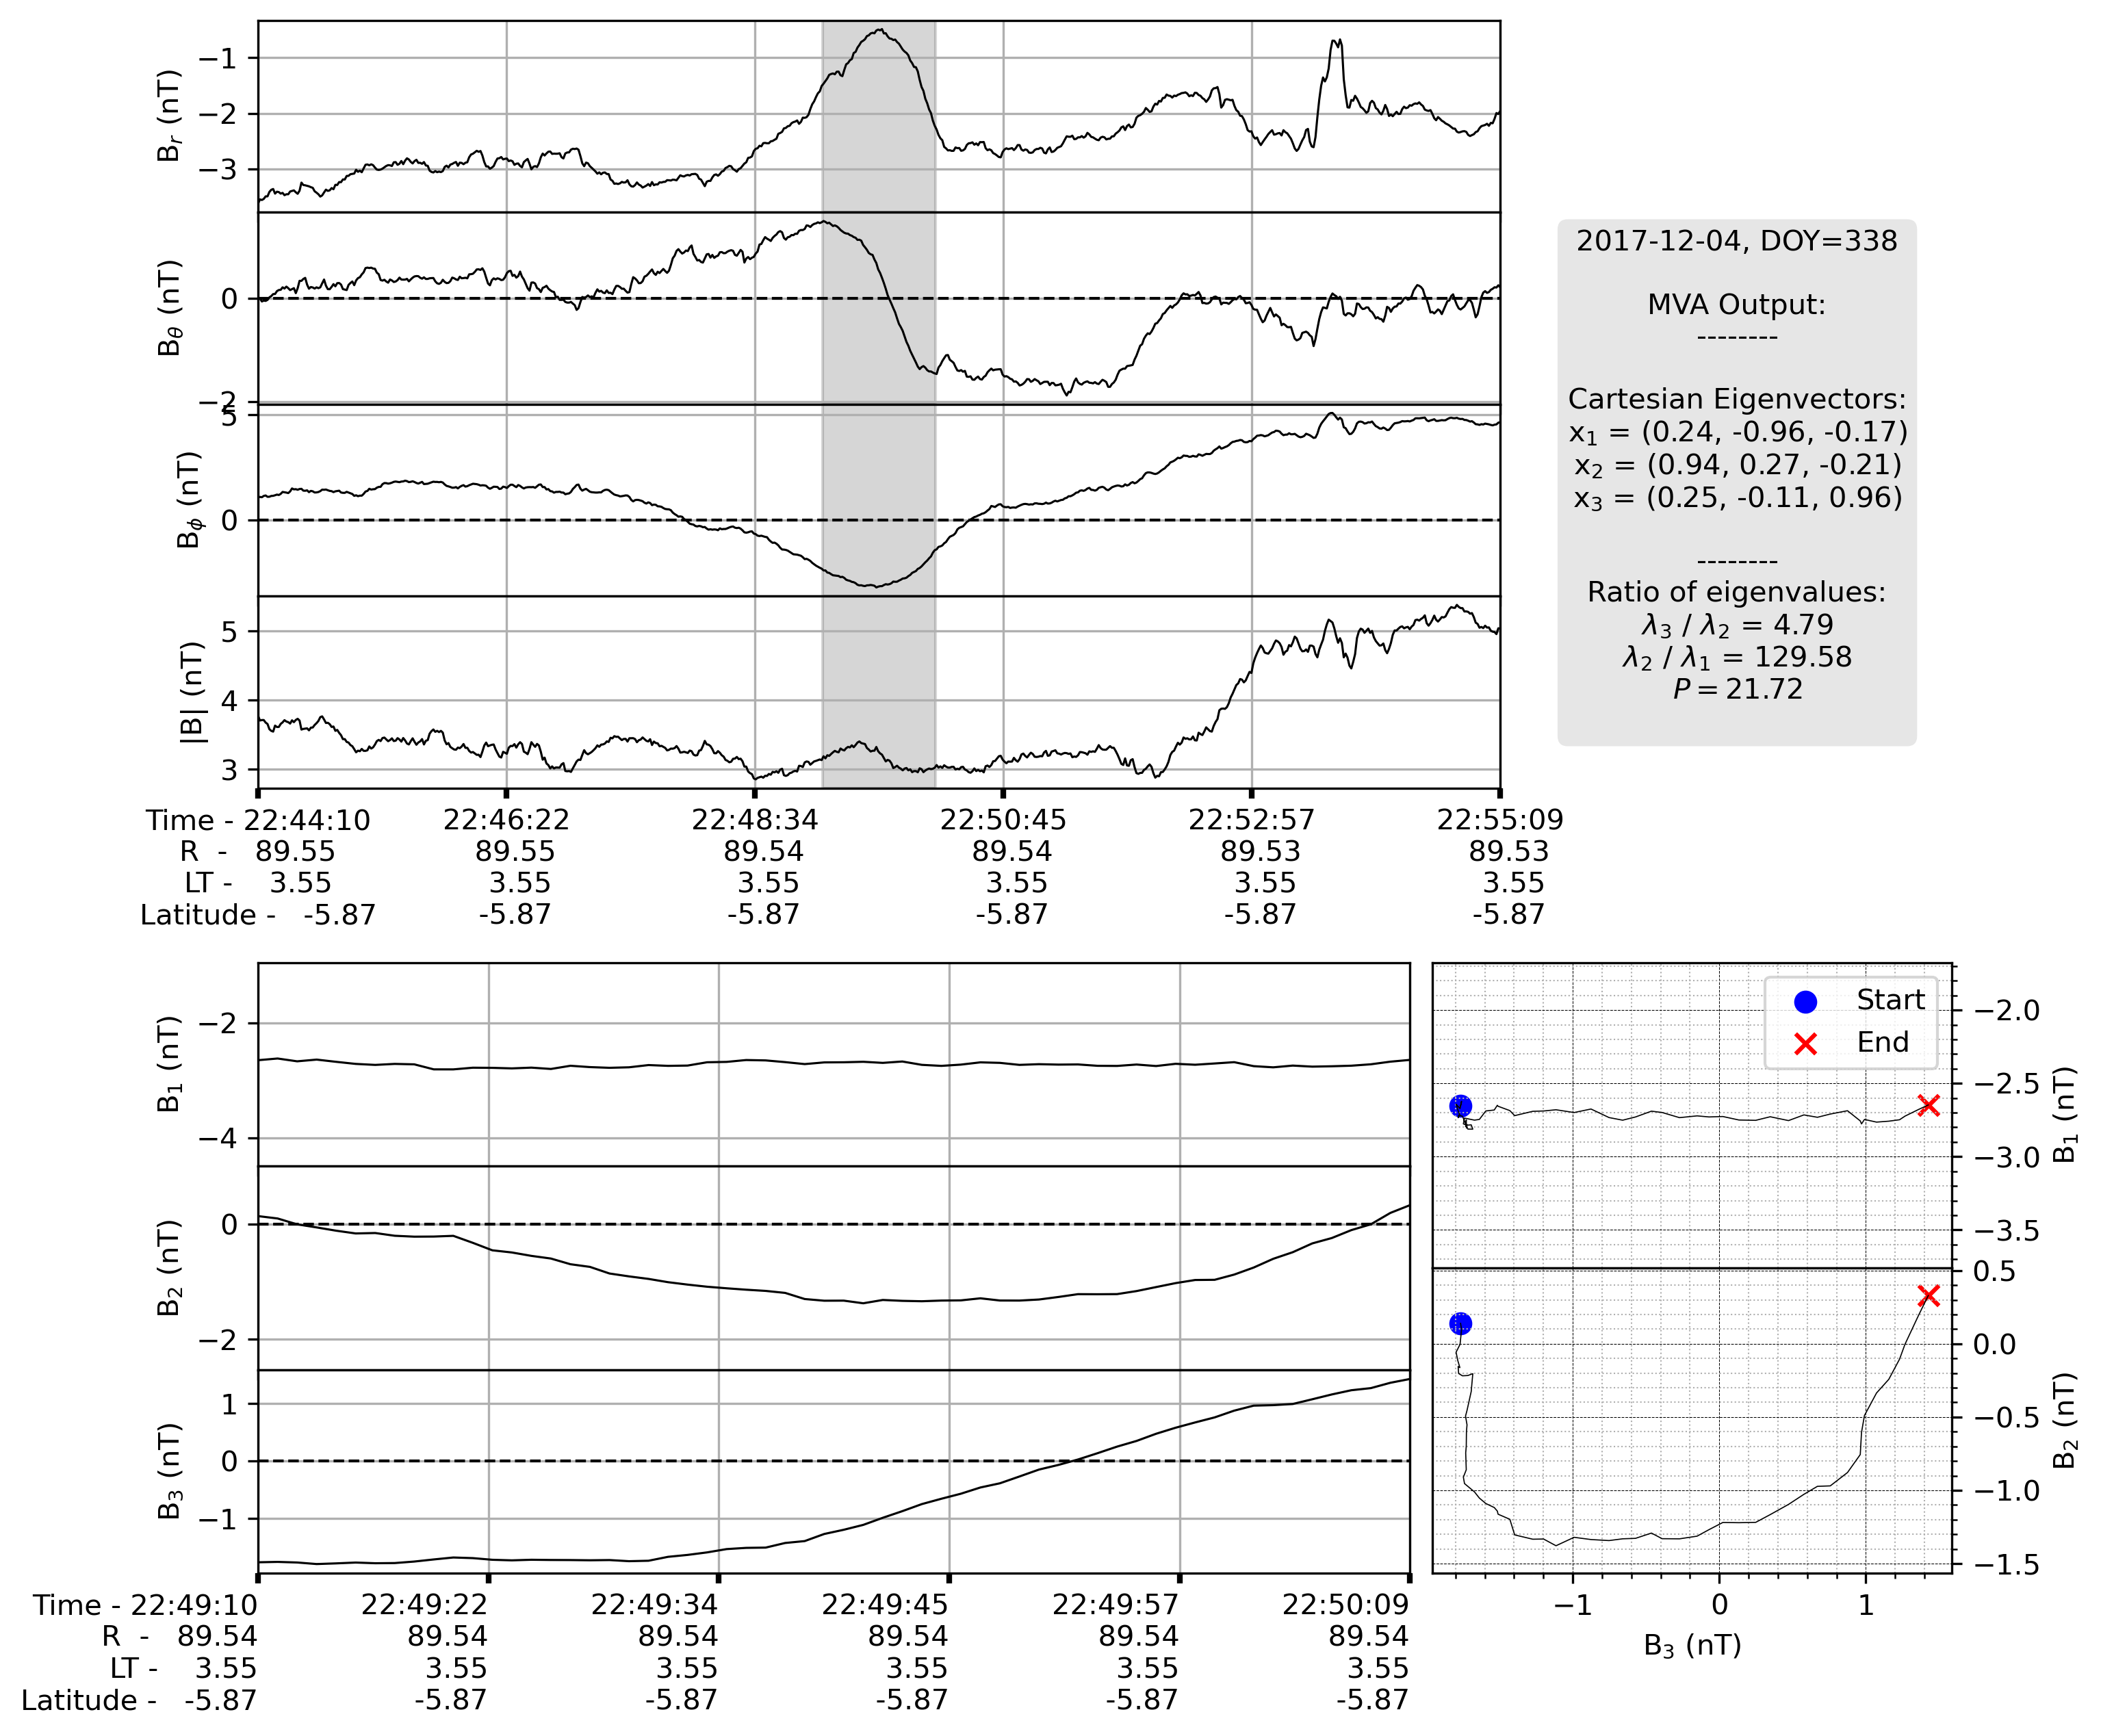

In [6]:
if not os.path.exists('out_mva'):
    os.mkdir('out_mva')
    
plot_mva_composite(magdata, magdata_mva, start, end, savefile=False)